# 03 · Классификаторы JNU по числам бланка

## tl;dr

Обучены **CatBoost с полным Grid Search**, **регуляризованная сплайновая модель с ограниченными взаимодействиями** и контрольная линейная логистика. Сравнение проводится отдельно для пяти наборов полей бланка. Цель — **экспертная normal/abnormal FIGO**, не диагноз гипоксии и не вероятность асфиксии.

Подбор: 5 внешних ×3 внутренних групповых фолда train, веса записей дают каждой пациентке суммарный вес 1. Агрегация single/ensemble5 выбирается внутри обучающей части. Калибровка и исследовательский порог используют две разные группы validation; test не выбирает решение. Все 20769 строк сохранены, фильтрации по флагу качества из 02 нет.

### Зафиксированные победители по каждому входному профилю

| Профиль | Модель, выбранная на train | Macro-F1 | Recall abnormal | Specificity | AP abnormal |
|---|---|---:|---:|---:|---:|
| minimal | spline_logit | 0.672 | 67.0% | 67.6% | 0.782 |
| variability | spline_logit | 0.721 | 70.8% | 73.7% | 0.823 |
| sonomed_fields | linear | 0.749 | 73.7% | 76.5% | 0.852 |
| mfmon_fields | spline_logit | 0.740 | 74.3% | 74.0% | 0.846 |
| mak_fields | spline_logit | 0.738 | 74.4% | 73.2% | 0.841 |

Оценка по **4140 test-записям 2520 пациенток**. Метрики по записям с суммарным весом 1 на пациентку — это не новая пациентская метка. Профиль выбирается по доступным проверенным полям; таблица не разрешает выбирать наиболее приятный риск.

«Идеальная» модель заранее неизвестна. Сплайны проверяют, достаточно ли плавных зависимостей и немногих взаимодействий; линейная модель может оказаться конкурентоспособной. Результат ограничен собственным экстрактором, одним центром и 30-минутной записью. Перенос на реальные российские бланки не подтверждён. [Подробная проверка, интервалы и устойчивость](04_classifier_assessment.ipynb).


## Context & Methods

### Key Assumptions

- Только поля отчёта. Нет FHR/UC, NetFea, клинических исходов/Апгар, ID, заключений прибора и внутренних quality-флагов в X. Независимость задаёт patient_component из 01.
- Внешний assessment не используется ни для fit преобразований, ни для выбора параметров/усреднения. Inner folds одинаковы для моделей. Пациентские веса пересчитываются в текущей fit/assessment-когорте.
- CatBoost: **72** комбинации depth/learning_rate/l2/iterations/class weights. Сплайновая логистика: **48** комбинаций числа узлов/регуляризации/взаимодействий/class weights. Линейный контроль: **10** комбинаций C/весов. Это исчерпывающий поиск по заданной конечной сетке, не Random Search и не гарантия глобального оптимума.
- Single/ensemble5: усреднение принимается при улучшении inner Macro-F1 минимум на 0.005 и ухудшении log loss не более 0.005. Проверка ансамбля внутри каждого inner fit использует собственные групповые подфолды, не модели, видевшие оцениваемую строку.
- Политика выбора зафиксирована до test: максимум среднего inner patient-weighted Macro-F1, точные равенства разрешает log loss/сложность. В отличие от предварительного плана эвристика одной стандартной ошибки не применяется: с тремя зависимыми фолдами это не формальный доверительный интервал. Изменение зафиксировано в protocol.json до обучения.
- CatBoost использует NaN и отдельные маски всех колонок; scaler не требуется. Сплайны/логистика fit собственные median/IQR и маски внутри fit. Параметры из 02 не используются.
- Сплайны строят квадратичные B-splines с удалением повторных квантильных узлов, явным поведением констант/бинарных полей и ограниченным набором пар. Для редких/нулевых счётчиков это устойчивее предположения уникальных квантилей.
- Калибровка actual aggregate: sigmoid(logit(p)) с положительным наклоном, fit только на validation-calibration. Порог 0.5 — primary; альтернативный F1-порог на validation-operating — исследовательский, не клинически «безопасный».

Первичные технические источники: [CatBoost parameters](https://catboost.ai/docs/en/references/training-parameters/common), [SplineTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html), [калибровка вероятностей](https://scikit-learn.org/stable/modules/calibration.html). Определения КТГ и границы переноса — [обзор 02](REPORT_FEATURE_METHODS.md).


In [3]:
from pathlib import Path
import sys,json,io,contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix,precision_recall_curve,roc_curve
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.training.jnu_report_experiment import OUT,EXPORT,metadata,inputs
from src.training.jnu_report_models import patient_weights
sns.set_theme(style='whitegrid',font_scale=1.02)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',100)
COLORS={'catboost':'#0072b2','spline_logit':'#d55e00','linear':'#009e73'}
def save_show(name):
    plt.gcf().savefig(OUT/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · фиксированное разбиение и запуск

Первый расчёт выполняет полный поиск. Повторный использует контрольные точки, привязанные к хешам кода/входов и версиям библиотек. После test изменение кода не может незаметно породить новый «слепой» результат в той же версии. Ход расчёта сохраняется в `progress.json`; полный вывод — в отдельный журнал.


In [5]:
from src.training.jnu_report_experiment import run_all
with (OUT/'notebook_training_replay.log').open('w') as log,contextlib.redirect_stdout(log):
    metrics=run_all()
protocol=json.loads((OUT/'protocol.json').read_text())
frozen=json.loads((OUT/'selection_frozen.json').read_text())
display(pd.DataFrame({'version':protocol['environment']}))
train,valid,test=[metadata(s) for s in ['train','validation','test']]
display(pd.DataFrame([{'split':name,'records':len(d),'patients':d.patient_id.nunique(),
    'normal':int((d.figo_label==0).sum()),'abnormal':int(d.figo_label.sum())}
    for name,d in zip(['train','validation','test'],[train,valid,test])]))
display(pd.read_csv(OUT/'outer_support.csv'))
print('Поиск и замороженная оценка завершены; все исходные строки сохранены.')


Поиск и замороженная оценка завершены; все исходные строки сохранены.


,version
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.9.1
catboost,1.2.10
joblib,1.6.0


,split,records,patients,normal,abnormal
0,train,12464,7564,5756,6708
1,validation,4165,2522,1921,2244
2,test,4140,2520,1921,2219


,outer_fold,part,records,patients,components,normal,abnormal
0,0,fit,9973,6051,6051,4606,5367
1,0,assessment,2491,1513,1513,1150,1341
2,1,fit,9973,6051,6051,4606,5367
3,1,assessment,2491,1513,1513,1150,1341
4,2,fit,9967,6061,6061,4603,5364
5,2,assessment,2497,1503,1503,1153,1344
6,3,fit,9971,6028,6028,4604,5367
7,3,assessment,2493,1536,1536,1152,1341
8,4,fit,9972,6065,6065,4605,5367
9,4,assessment,2492,1499,1499,1151,1341


## Results · честные внешние фолды train

Точки — внешние фолды после inner подбора параметров и режима агрегации. Линии погрешности — **SD пяти фолдов**, не 95% CI и не независимые повторные эксперименты. Итоговая семья внутри профиля выбирается по этому train-сравнению, а не по test.


,profile,family,mean_f1,sd_f1,mean_ap,mean_recall,mean_log_loss
0,mak_fields,catboost,0.7378,0.0061,0.8497,0.7478,0.5161
1,mak_fields,linear,0.7300,0.0047,0.8439,0.7092,0.5274
2,mak_fields,spline_logit,0.7401,0.0081,0.8525,0.7431,0.5130
3,mfmon_fields,catboost,0.7409,0.0052,0.8526,0.7415,0.5121
4,mfmon_fields,linear,0.7372,0.0050,0.8519,0.7165,0.5174
5,mfmon_fields,spline_logit,0.7409,0.0048,0.8560,0.7415,0.5093
6,minimal,catboost,0.6716,0.0062,0.7878,0.5840,0.5923
7,minimal,linear,0.6690,0.0043,0.7829,0.6085,0.5985
8,minimal,spline_logit,0.6752,0.0059,0.7883,0.6429,0.5903
9,sonomed_fields,catboost,0.7480,0.0059,0.8604,0.7465,0.5021


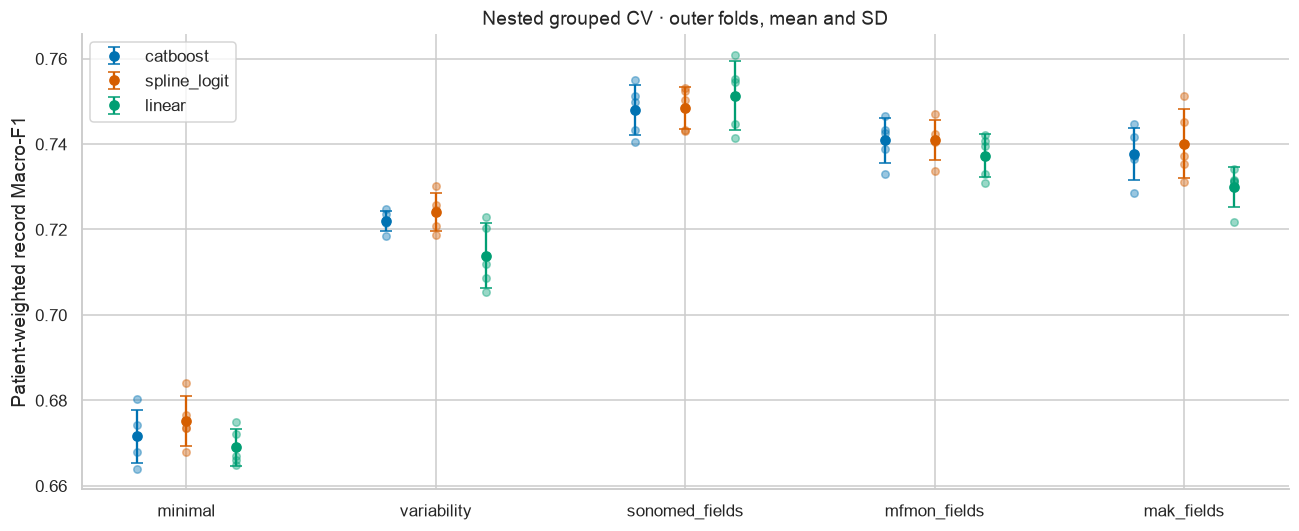

In [7]:
nested=pd.read_csv(OUT/'nested_summary.csv')
folds=pd.read_csv(OUT/'nested_fold_metrics.csv')
display(nested.round(4))
profiles=list(protocol['profiles'])
fig,ax=plt.subplots(figsize=(12,5))
for j,family in enumerate(['catboost','spline_logit','linear']):
    for i,profile in enumerate(profiles):
        values=folds[(folds.profile==profile)&(folds.family==family)].patient_macro_f1
        pos=i+(j-1)*.2
        ax.scatter(np.full(len(values),pos),values,s=24,color=COLORS[family],alpha=.4)
        ax.errorbar(pos,values.mean(),yerr=values.std(),fmt='o',capsize=4,color=COLORS[family],label=family if i==0 else None)
ax.set(xticks=range(len(profiles)),xticklabels=profiles,ylabel='Patient-weighted record Macro-F1',title='Nested grouped CV · outer folds, mean and SD')
ax.legend();fig.tight_layout();save_show('01_nested_folds.png')


### Сетки и зафиксированные конфигурации

Карты показывают лучший mean inner score по остальным параметрам при заданной паре осей. Это диагностический срез **train-CV**, не test и не новое основание менять конфигурацию. Для iterations=300 использован точный префикс fit на 700 деревьев при одинаковых остальных параметрах/seed; все 36 соответствий проверяются отдельно на реальных train-данных.


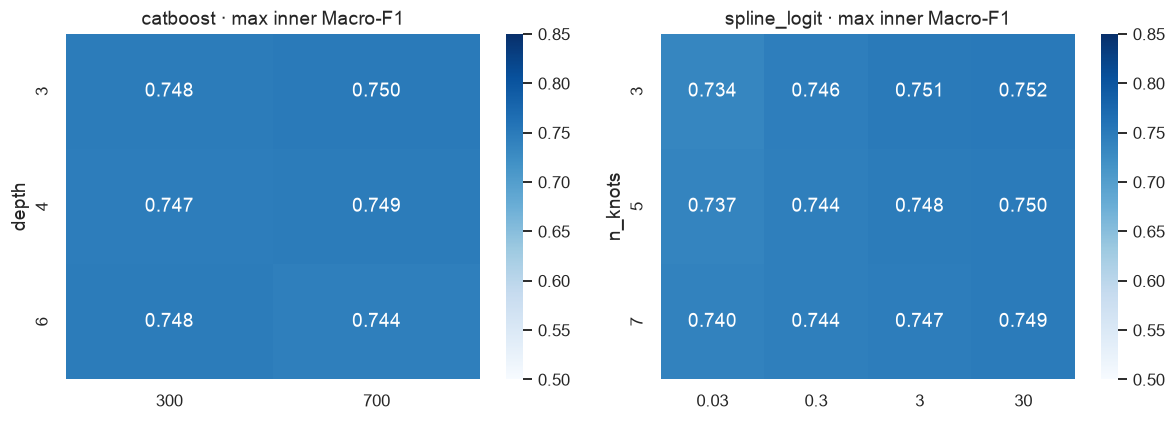

,profile,family,mode,champion,params,research_threshold
0,minimal,catboost,single,False,"{'auto_class_weights': 'SqrtBalanced', 'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.03, 'it...",0.510403
1,minimal,spline_logit,single,True,"{'C': 30.0, 'interactions': True, 'n_knots': 3, 'weight_policy': None}",0.531519
2,minimal,linear,single,False,"{'C': 1.0, 'weight_policy': None}",0.525439
3,variability,catboost,single,False,"{'auto_class_weights': None, 'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.03, 'iterations':...",0.484640
4,variability,spline_logit,single,True,"{'C': 30.0, 'interactions': False, 'n_knots': 5, 'weight_policy': None}",0.493483
5,variability,linear,single,False,"{'C': 0.1, 'weight_policy': None}",0.514398
6,sonomed_fields,catboost,single,False,"{'auto_class_weights': None, 'depth': 3, 'l2_leaf_reg': 3, 'learning_rate': 0.03, 'iterations': ...",0.545629
7,sonomed_fields,spline_logit,single,False,"{'C': 30.0, 'interactions': False, 'n_knots': 3, 'weight_policy': None}",0.541713
8,sonomed_fields,linear,single,True,"{'C': 10.0, 'weight_policy': None}",0.491765
9,mfmon_fields,catboost,single,False,"{'auto_class_weights': 'SqrtBalanced', 'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'ite...",0.505511


In [9]:
grid=pd.read_json(OUT/'final_grid_results.json')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,family,row,col in [(axes[0],'catboost','depth','iterations'),(axes[1],'spline_logit','n_knots','C')]:
    selected=grid[(grid.profile=='sonomed_fields')&(grid.family==family)].copy()
    selected=pd.concat([selected.drop(columns='params').reset_index(drop=True),pd.json_normalize(selected.params).reset_index(drop=True)],axis=1)
    heat=selected.groupby([row,col]).mean_f1.max().unstack(col)
    heat.columns=[f'{v:g}' for v in heat.columns]
    sns.heatmap(heat,annot=True,fmt='.3f',cmap='Blues',ax=ax,vmin=.5,vmax=.85)
    ax.tick_params(axis='x',labelrotation=0)
    ax.set_title(f'{family} · max inner Macro-F1')
fig.tight_layout();save_show('02_parameter_grids.png')
choices=pd.DataFrame(json.loads((OUT/'final_choices.json').read_text()))
display(choices[['profile','family','mode','champion','params','research_threshold']])


### Однократная оценка test после фиксации

Основная таблица использует калиброванные вероятности и порог 0.5. Представлены все заранее объявленные модели, победитель помечен **по train**. Второй порог выбран на отдельной validation-operating части и не означает клинический порог. Метрики record_* и patient_* рассчитываются по тем же записям, но с разным весом повторных исследований.


,profile,family,champion,patient_macro_f1,patient_recall,patient_specificity,patient_precision,patient_ap,patient_brier,record_macro_f1
0,minimal,catboost,False,0.6723,0.6370,0.7147,0.7263,0.7869,0.2053,0.6727
2,minimal,spline_logit,True,0.6719,0.6702,0.6760,0.7109,0.7818,0.2055,0.6721
4,minimal,linear,False,0.6710,0.6598,0.6857,0.7139,0.7814,0.2077,0.6697
6,variability,catboost,False,0.7194,0.7174,0.7239,0.7555,0.8307,0.1843,0.7238
8,variability,spline_logit,True,0.7207,0.7079,0.7373,0.7621,0.8234,0.1853,0.7236
10,variability,linear,False,0.7088,0.6971,0.7241,0.7502,0.8203,0.1907,0.7111
12,sonomed_fields,catboost,False,0.7508,0.7623,0.7403,0.7772,0.8556,0.1691,0.7531
14,sonomed_fields,spline_logit,False,0.7507,0.7511,0.7526,0.7830,0.8538,0.1679,0.7545
16,sonomed_fields,linear,True,0.7492,0.7375,0.7645,0.7883,0.8523,0.1695,0.7531
18,mfmon_fields,catboost,False,0.7471,0.7664,0.7280,0.7701,0.8488,0.1715,0.7487


,profile,family,threshold,patient_macro_f1,patient_recall,patient_specificity
3,minimal,spline_logit,0.5315,0.6727,0.6031,0.7557
9,variability,spline_logit,0.4935,0.7215,0.7181,0.7277
17,sonomed_fields,linear,0.4918,0.7496,0.7467,0.7549
21,mfmon_fields,spline_logit,0.5178,0.7397,0.7256,0.7577
27,mak_fields,spline_logit,0.5466,0.7359,0.6940,0.7860


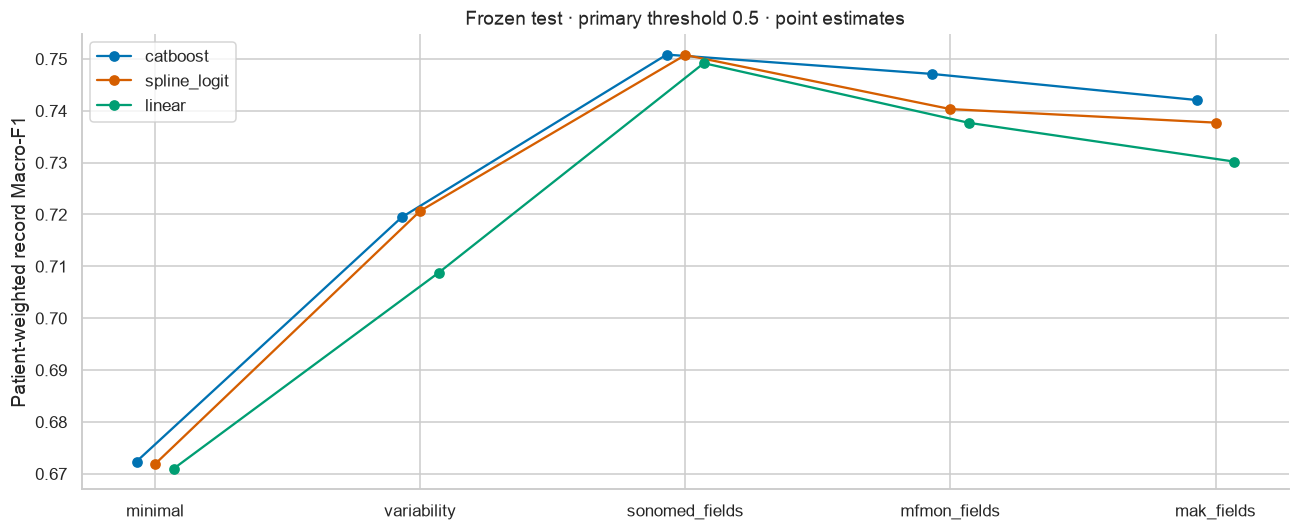

In [11]:
primary=metrics[metrics.policy=='primary_0.5'].copy()
display(primary[['profile','family','champion','patient_macro_f1','patient_recall','patient_specificity','patient_precision','patient_ap','patient_brier','record_macro_f1']].round(4))
alternate=metrics[(metrics.policy=='research_macro_threshold')&metrics.champion.astype(bool)]
display(alternate[['profile','family','threshold','patient_macro_f1','patient_recall','patient_specificity']].round(4))
fig,ax=plt.subplots(figsize=(12,5))
for j,family in enumerate(['catboost','spline_logit','linear']):
    rows=primary[primary.family==family].set_index('profile').loc[profiles]
    ax.plot(np.arange(len(profiles))+(j-1)*.07,rows.patient_macro_f1,'o-',color=COLORS[family],label=family)
ax.set(xticks=range(len(profiles)),xticklabels=profiles,ylabel='Patient-weighted record Macro-F1',title='Frozen test · primary threshold 0.5 · point estimates')
ax.legend();fig.tight_layout();save_show('03_frozen_test_comparison.png')


### Какие ошибки остаются · расширенный профиль

Все 4140 записей test, включая неполные входы, входят в знаменатель. В 04 отдельно показана доля отсутствующего core и технический отказ для таких бланков. На матрице число записей и доля внутри истинного класса; это экспертная FIGO-разметка, не клинические диагнозы.


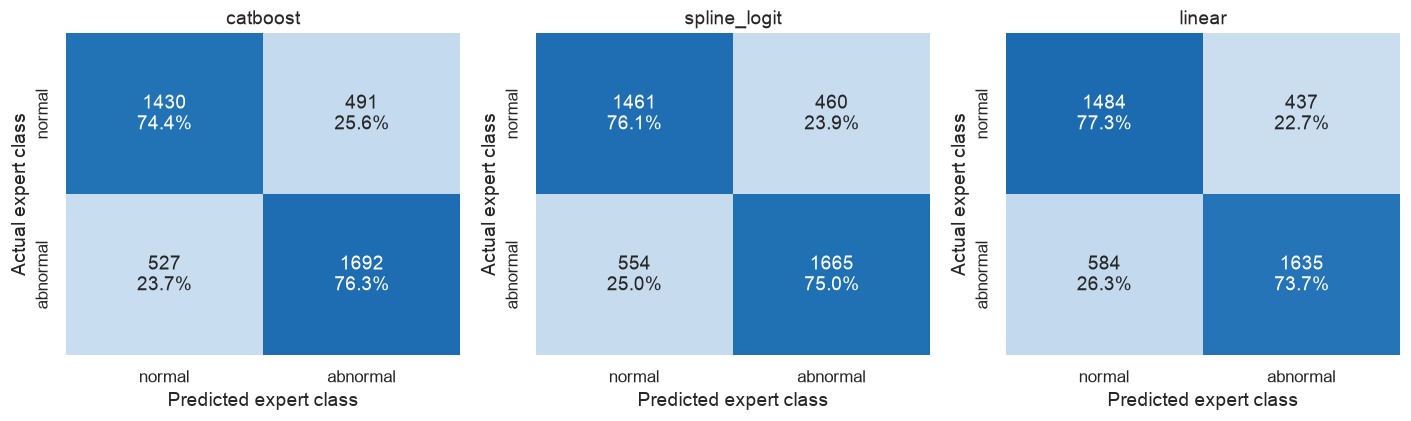

In [13]:
pred=pd.read_parquet(OUT/'test_predictions.parquet')
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,family in zip(axes,['catboost','spline_logit','linear']):
    d=pred[(pred.profile=='sonomed_fields')&(pred.family==family)]
    cm=confusion_matrix(d.figo_label,d.p>=.5,labels=[0,1]);percent=cm/cm.sum(axis=1,keepdims=True)
    annotations=np.array([[f'{cm[i,j]}\n{percent[i,j]:.1%}' for j in range(2)] for i in range(2)])
    sns.heatmap(percent,annot=annotations,fmt='',cmap='Blues',vmin=0,vmax=1,cbar=False,ax=ax,
        xticklabels=['normal','abnormal'],yticklabels=['normal','abnormal'])
    ax.set(title=family,xlabel='Predicted expert class',ylabel='Actual expert class')
fig.tight_layout();save_show('04_test_confusion.png')


### Что выучили модели · наблюдаемые зависимости

Показаны средние вероятности на **реальных train-строках**, сгруппированных по квантилям одного измерения, и доля экспертных abnormal в тех же группах; веса дают пациентке суммарно 1. Остальные поля сохраняются как наблюдались: искусственное изменение одного STV(ms) при фиксированном STV(BPM) нарушило бы связь единиц. Это описательные зависимости с коррелирующими признаками, **не причинный эффект и не оценка качества на новых данных**. Здесь заранее показан расширенный профиль. Train уже участвовал в fit; этот рисунок не выбирает новые признаки или модель.


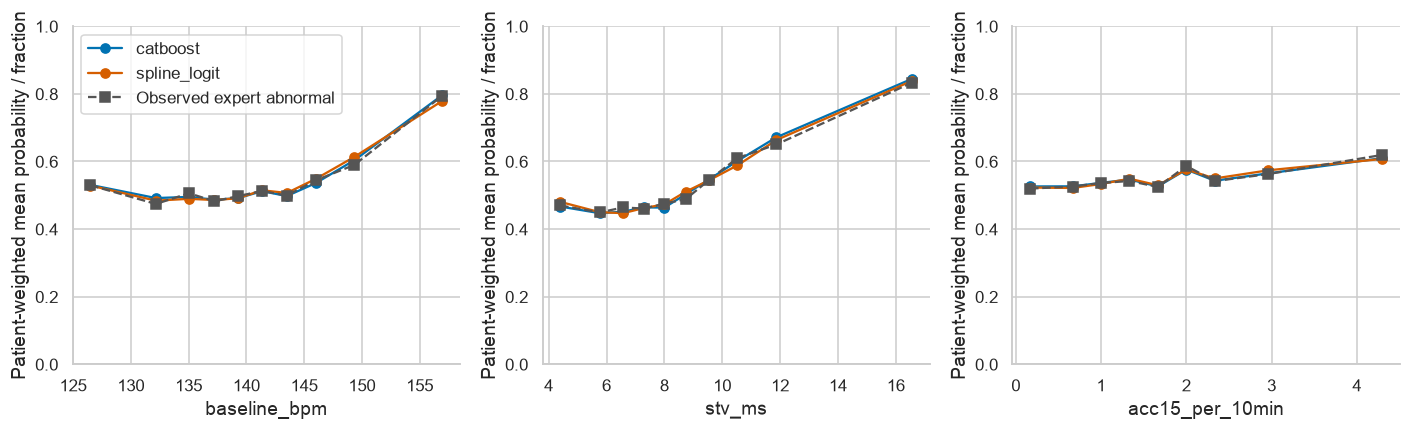

In [15]:
profile='sonomed_fields';xt=inputs(train,profile)
models={f:joblib.load(EXPORT/f'{profile}_{f}.joblib') for f in ['catboost','spline_logit']}
fitted={f:bundle.predict_proba(xt)[:,1] for f,bundle in models.items()}
w=patient_weights(train.patient_id);y=train.figo_label.to_numpy()
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,col in zip(axes,['baseline_bpm','stv_ms','acc15_per_10min']):
    bins=pd.qcut(xt[col],10,duplicates='drop');summary=[]
    for group in bins.cat.categories:
        mask=(bins==group).to_numpy()
        summary.append(dict(x=np.average(xt.loc[mask,col],weights=w[mask]),
            observed=np.average(y[mask],weights=w[mask]),
            **{f:np.average(p[mask],weights=w[mask]) for f,p in fitted.items()}))
    means=pd.DataFrame(summary)
    for family in models:ax.plot(means.x,means[family],'o-',color=COLORS[family],label=family)
    ax.plot(means.x,means.observed,'s--',color='#555555',label='Observed expert abnormal')
    ax.set(xlabel=col,ylabel='Patient-weighted mean probability / fraction',ylim=(0,1))
axes[0].legend();fig.tight_layout();save_show('05_conditional_response.png')


### Экспорт и границы применения

Сохранены полные bundles с калибратором, native CatBoost и **отдельные fit-преобразования** каждой сплайновой/линейной модели. В ансамбле у каждого участника собственные fitted параметры. Model cards фиксируют цель, колонки, параметры, длительность и ограничения. [04](04_classifier_assessment.ipynb) независимо сверяет эти файлы.


In [17]:
display(pd.DataFrame({'profile':list(frozen['champions']),'train_selected_family':list(frozen['champions'].values())}))
print('Экспорты:',EXPORT.relative_to(ROOT))
print('Исходы неонатальной асфиксии не являются целью этого запуска.')
print('Неизвестный прибор, 17-min бланк и клинический риск не получили валидацию от этих внутренних оценок.')


Экспорты: models/exported/jnu_ctg/classifiers_v1
Исходы неонатальной асфиксии не являются целью этого запуска.
Неизвестный прибор, 17-min бланк и клинический риск не получили валидацию от этих внутренних оценок.


,profile,train_selected_family
0,minimal,spline_logit
1,variability,spline_logit
2,sonomed_fields,linear
3,mfmon_fields,spline_logit
4,mak_fields,spline_logit


## Takeaways

- Получены проверяемые кандидаты для каждого доступного набора полей. Полная конечная сетка и все результаты сохранены; результат зависит от информации на бланке.
- Второй подход проверяет плавные зависимости с регуляризацией. Его преимущество над CatBoost не предполагается заранее; линейный контроль может выигрывать на части профилей.
- В расширенном профиле CatBoost и сплайны дали F1 около 0.751; на train выбран линейный контроль (test 0.749), и этот выбор не подменяется test-максимумом. Для трёх полей F1 около 0.672, для пяти — 0.721. Добавление информации существенно полезнее наблюдаемой разницы семейств.
- Все финальные решения сохранили single: пять усредняемых моделей не дали достаточной пользы по предварительному критерию. Калибровка не обязана улучшать каждую test-метрику: raw/sigmoid сравнение полностью показано в 04, решения по test не отменяются.
- Отбор по качеству не уменьшал ни train, ни test. Неизвестные значения сопровождались масками, а все fit-преобразования обучались внутри групп.
- Это внутренние оценки expert normal/abnormal на JNU, а не решение о здоровье плода. До работы с реальными больничными цифрами нужны подтверждение измерений и внешняя дородовая валидация. Честные интервалы/ошибки/стресс-проверки — в следующем выполненном ноутбуке.
